# Candidate Search (Full Evaluation Log)

Mine `all_evaluations.csv` — every molecule evaluated during a CMA-MAE run — for antibiotic candidates.

Unlike `archive_explorer.ipynb` (which triages the ~180-molecule `result_archive.csv` curated by the QD grid), this notebook starts from the **full evaluation pool** (hundreds of thousands of unique molecules with real, uncapped P(active)) and applies its own filters:

**load → dedup → novelty filter → P(active) threshold → cluster → cytotox → AD → retrosynthesis → composite rank.**

Reuses helpers from `notebooks/archive_explorer.py` and `notebooks/eva_utils.py`.

## Setup

In [4]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger

from notebooks.archive_explorer import (
    add_cytotox_scores,
    best_per_cluster,
    draw_grid,
    load_training_actives,
    rank_composite,
    remove_training_molecules,
    tag_with_clusters,
    aizynth_score,
)
from notebooks.eva_utils import check_halogenated_benzoic_acid, compute_morgan_fps


RDLogger.DisableLog("rdApp.*")

REPO_ROOT = Path("..").resolve()
TRAINING_CSV = REPO_ROOT / "data" / "predictor" / "predictor_training_data.csv"
CYTOTOX_3T3 = REPO_ROOT / "data" / "cytotox" / "tabpfn_3T3.joblib"
CYTOTOX_HEK = REPO_ROOT / "data" / "cytotox" / "tabpfn_HEK.joblib"
AD_MODEL = REPO_ROOT / "data" / "predictor" / "ad_model.joblib"

RUN = "cmamae_max_partial_charge_baseline"
EVAL_CSV = REPO_ROOT / "results" / RUN / "all_evaluations.csv"

# Filters
P_ACTIVE_MIN = 0.6  # activity threshold (matches archive_explorer)
NOVELTY_MAX_SIM = 0.5  # drop molecules with max Tanimoto to training >= this
CLUSTER_THRESHOLD = 0.65  # Butina distance cutoff (1 - Tanimoto)
N_PER_CLUSTER = 3  # top-N per cluster sent to retrosynthesis
RETRO_CAP = 100  # hard cap on number of retrosynthesis runs

## Load all_evaluations.csv

Every evaluated molecule from the run: `eval, smiles, p_active, valid, gen`.
Only valid (parseable) molecules are kept.

In [5]:
raw = pd.read_csv(EVAL_CSV, usecols=["eval", "smiles", "p_active", "valid", "gen"])
raw = raw[raw["valid"]].copy()
print(f"{RUN}: {len(raw):,} valid evaluations")
print(
    f"p_active: min={raw['p_active'].min():.3f}, "
    f"median={raw['p_active'].median():.3f}, "
    f"max={raw['p_active'].max():.3f}"
)

cmamae_max_partial_charge_baseline: 372,139 valid evaluations
p_active: min=0.044, median=0.163, max=0.923


## Filter to P(active) > P_ACTIVE_MIN

In [6]:
raw = raw[raw["p_active"] > P_ACTIVE_MIN].copy().reset_index(drop=True)
print(f"Candidates (P>{P_ACTIVE_MIN}): {len(raw):,}")

Candidates (P>0.6): 290


## Deduplicate (best P(active) per canonical SMILES)

Raw decoded SMILES repeat in non-canonical forms. Canonicalize, then keep the
best P(active) per molecule. TabPFN is non-deterministic (~3.6e-4), so the same
SMILES gets slightly different scores across evaluations — `max` matches the
`best_score` convention from `does_optimization_help.ipynb`.

In [7]:
def _canonical(smi):
    m = Chem.MolFromSmiles(smi)
    return Chem.MolToSmiles(m) if m else None


raw["canonical"] = raw["smiles"].apply(_canonical)
raw = raw.dropna(subset=["canonical"])

deduped = (
    raw.groupby("canonical", as_index=False)
    .agg(
        p_active=("p_active", "max"),
        first_gen=("gen", "min"),
        last_gen=("gen", "max"),
        n_evals=("eval", "count"),
    )
    .rename(columns={"canonical": "smiles"})
)
print(f"Unique molecules: {len(deduped):,}")

Unique molecules: 274


## Remove training molecules

In [8]:
training_actives = load_training_actives(TRAINING_CSV)
candidates = remove_training_molecules(deduped, training_actives)
print(f"Novel (non-training): {len(candidates):,} / {len(deduped):,}")

Novel (non-training): 262 / 274


## Max Tanimoto similarity to training set (novelty filter)

Keep molecules whose max similarity to any training active is below
`NOVELTY_MAX_SIM` (0.8) — removes near-duplicates of known actives.

Vectorized via matrix multiplication (chunked to bound memory). The naive
`max_tanimoto_to_set` loop is infeasible at this scale (158k × 2.9k
comparisons); this runs in seconds on the filtered candidate set.

In [9]:
ref_smiles = sorted(training_actives)
ref_fps = compute_morgan_fps(ref_smiles)
ref_sums = ref_fps.sum(axis=1)

q_fps = compute_morgan_fps(candidates["smiles"].tolist())

CHUNK = 4096
max_sims = np.empty(len(candidates), dtype=np.float32)
most_similar = [""] * len(candidates)
for s in range(0, len(candidates), CHUNK):
    e = min(s + CHUNK, len(candidates))
    q = q_fps[s:e]
    inter = q @ ref_fps.T
    union = q.sum(axis=1)[:, None] + ref_sums[None, :] - inter
    sim = inter / (union + 1e-8)
    best_j = sim.argmax(axis=1)
    max_sims[s:e] = sim[np.arange(e - s), best_j]
    for i, j in enumerate(best_j):
        most_similar[s + i] = ref_smiles[j]

candidates["max_tanimoto_similarity"] = max_sims
candidates["similar_training_smiles"] = most_similar
print(
    f"Max sim: min={max_sims.min():.3f}, "
    f"median={np.median(max_sims):.3f}, "
    f"max={max_sims.max():.3f}"
)

before = len(candidates)
candidates = candidates[
    candidates["max_tanimoto_similarity"] < NOVELTY_MAX_SIM
].reset_index(drop=True)
print(f"After novelty filter (<{NOVELTY_MAX_SIM}): {len(candidates):,} / {before:,}")

ModuleNotFoundError: No module named 'chemistry.fingerprint'

## Tag aryl-acid-halogen motif

In [10]:
candidates["has_aryl_acid_halogen"] = candidates["smiles"].apply(
    check_halogenated_benzoic_acid
)
print(candidates["has_aryl_acid_halogen"].value_counts())

has_aryl_acid_halogen
False    262
Name: count, dtype: int64


## Cluster (Butina 0.65)

In [8]:
candidates = tag_with_clusters(candidates, threshold=CLUSTER_THRESHOLD)
print(f"Clusters: {candidates['cluster_id'].nunique()}")
print(candidates.groupby("cluster_id")["cluster_size"].first().describe())

Clusters: 237
count    237.000000
mean       9.662447
std       26.924643
min        1.000000
25%        1.000000
50%        2.000000
75%        5.000000
max      221.000000
Name: cluster_size, dtype: float64


In [9]:
candidates

,smiles,p_active,first_gen,last_gen,n_evals,max_tanimoto_similarity,similar_training_smiles,has_aryl_acid_halogen,cluster_id,cluster_size
0,C=C1CCCCC1C=CSCC(=O)Nc1cc(Br)cc(Cl)c1C(=O)O,0.637976,429,429,1,0.323944,O=C(CCC1CCCCC1)Nc1cc(Br)ccc1C(=O)O,True,160,1
1,C=C1CCCCCCC1CC(=O)Nc1cc(Cl)cc(Cl)c1C(=O)O,0.621876,810,810,1,0.393443,O=C(CCC1CCCCC1)Nc1cc(Cl)ccc1C(=O)O,True,186,1
2,C=CC=CCc1ccccc1C=CC(=O)Nc1cc(Br)cc(Br)c1C(=O)O,0.613108,652,652,1,0.328358,O=C(/C=C/c1ccccc1[N+](=O)[O-])Nc1ccc(Br)cc1,True,3,221
3,C=CC=CCc1ccccc1CC(=O)Nc1cc(Br)cc(Br)c1C(=O)O,0.673032,272,272,1,0.308824,O=C(COc1ccc2ccccc2c1)Nc1ccc(Br)cc1C(=O)O,True,10,95
4,C=CC=CSc1ccccc1C(=O)Nc1cc(Br)cc(Br)c1C(=O)O,0.627519,270,270,1,0.322581,O=C(Nc1ccc(Br)cc1C(=O)O)c1ccc(-c2ccccc2)cc1,True,7,32
...,...,...,...,...,...,...,...,...,...,...
2285,O=C(O)c1ccc(Br)cc1NC=CSCCCc1ccccc1,0.684317,242,242,1,0.421053,O=C(CCCc1ccccc1)Nc1cc(Cl)ccc1C(=O)O,True,93,1
2286,O=C(O)c1ccc(Br)cc1Nc1ccccc1CC1CC=CS1,0.658180,788,788,1,0.387097,O=C(CCC1CCCCC1)Nc1cc(Br)ccc1C(=O)O,True,80,12
2287,O=C(O)c1ccc(Cl)cc1-c1ccc(-c2ccccc2)s1,0.611004,34,34,1,0.411765,O=C(Nc1cc(-c2ccccc2)sc1C(=O)O)c1cccc(Cl)c1,True,21,10
2288,O=C(O)c1ccc(Cl)cc1NC(=S)CCCC1CC=CS1,0.619243,794,794,1,0.466667,O=C(CCC1CCCCC1)Nc1cc(Cl)ccc1C(=O)O,True,0,130


## Top by P(active)

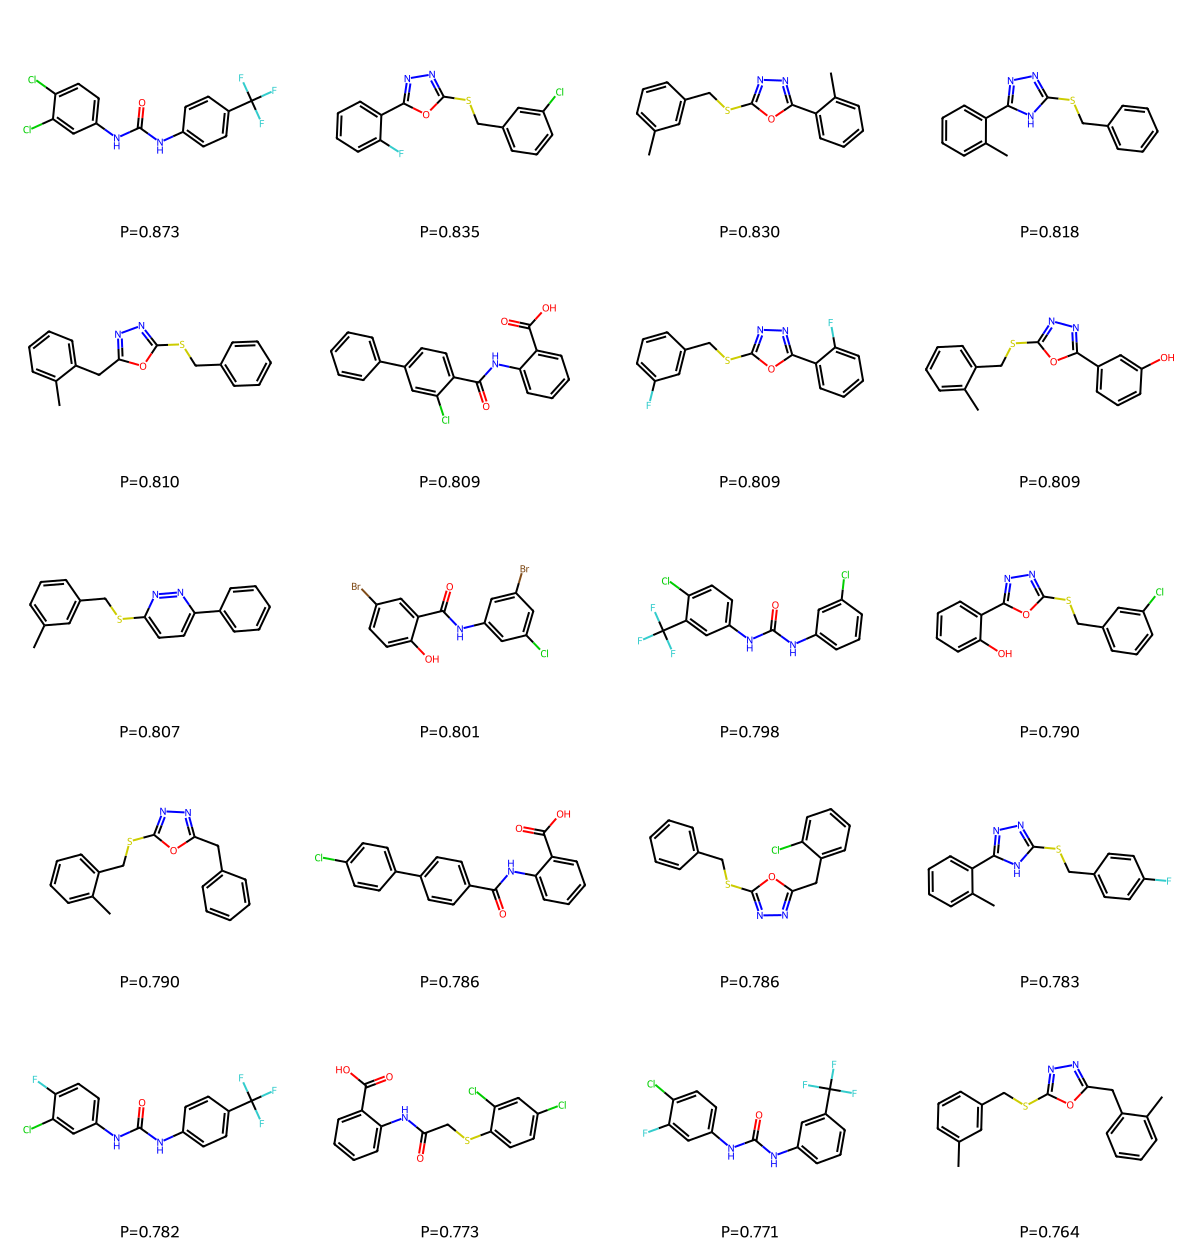

In [11]:
top = candidates.sort_values("p_active", ascending=False).head(20)
draw_grid(
    top["smiles"].tolist(),
    mols_per_row=4,
    titles=[f"P={p:.3f}" for p in top["p_active"]],
)

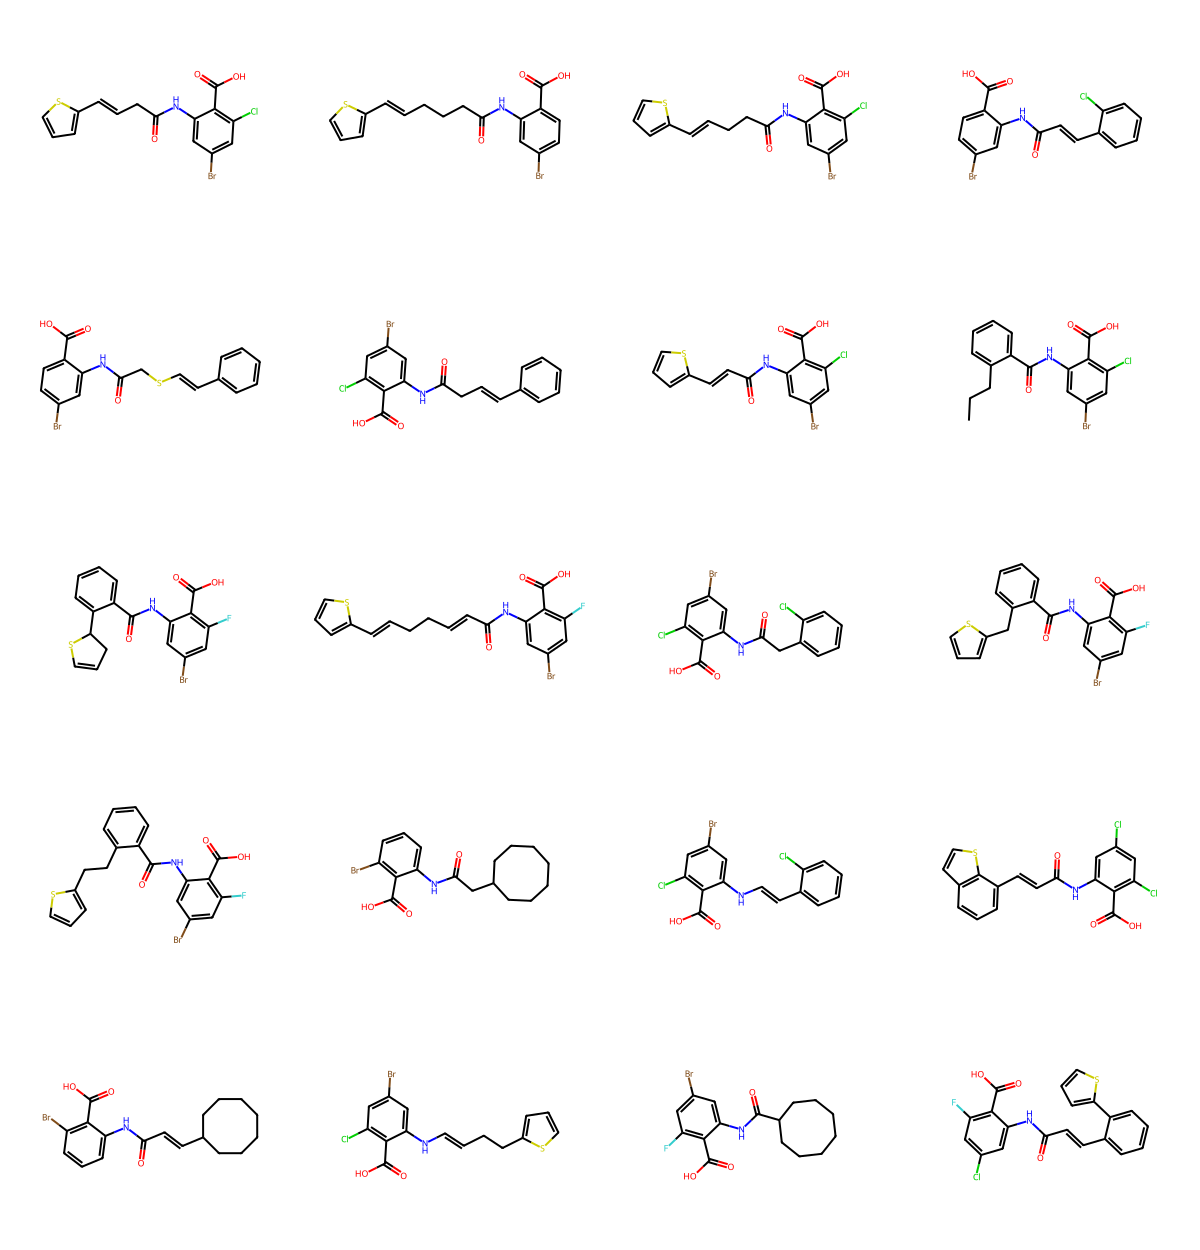

In [11]:
# make a list with 10 molecules (1 per cluster)for the first 10 molecules
molecules = []

for cluster_id, group in candidates.groupby("cluster_id"):
    if len(molecules) >= 20:
        break
    top_mol = group.sort_values("p_active", ascending=False).iloc[0]
    molecules.append(top_mol["smiles"])

draw_grid(molecules)

## Cytotoxicity scoring (3T3 + HEK)

In [56]:
candidates = add_cytotox_scores(candidates, CYTOTOX_3T3, column_name="p_cytotox_3T3")
candidates = add_cytotox_scores(candidates, CYTOTOX_HEK, column_name="p_cytotox_HEK")
print(f"3T3: mean={candidates['p_cytotox_3T3'].mean():.3f}")
print(f"HEK: mean={candidates['p_cytotox_HEK'].mean():.3f}")

ModuleNotFoundError: No module named 'evaluation.model_utils'

## AD score

In [ ]:
ad = ADScorer(model_path=AD_MODEL)
fps_arr, valid_idx = smiles_to_morgan(candidates["smiles"].tolist())
ad_scores = np.ones(len(candidates))
if len(fps_arr):
    ad_scores[valid_idx] = ad.compute_from_fps(fps_arr)
candidates["ad_score"] = ad_scores
print(f"AD: mean={candidates['ad_score'].mean():.3f}")

## Composite ranking (pre-retrosynthesis)

Rank by P(active) (higher better) vs cytotoxicity + AD (lower better). Used to
pick which molecules to send to retrosynthesis.

In [ ]:
candidates = rank_composite(
    candidates,
    higher_better=["p_active"],
    lower_better=["p_cytotox_3T3", "p_cytotox_HEK"],
    weights={"p_active": 4, "p_cytotox_3T3": 1, "p_cytotox_HEK": 1},
)
candidates = candidates.sort_values("rank_composite").reset_index(drop=True)

## Top-N per cluster for retrosynthesis

Retrosynthesis (AiZynthFinder, 120 s/mol) is the bottleneck — only the top
`N_PER_CLUSTER` per Butina cluster are sent, capped at `RETRO_CAP` total.

In [ ]:
retro_candidates = (
    candidates.sort_values("rank_composite")
    .groupby("cluster_id", as_index=False)
    .head(N_PER_CLUSTER)
    .reset_index(drop=True)
)
if len(retro_candidates) > RETRO_CAP:
    retro_candidates = retro_candidates.head(RETRO_CAP).reset_index(drop=True)
print(
    f"Retrosynthesis pool: {len(retro_candidates)} molecules across "
    f"{retro_candidates['cluster_id'].nunique()} clusters"
)
draw_grid(
    retro_candidates["smiles"].tolist(),
    mols_per_row=4,
    titles=[
        f"C{int(c)} P={p:.3f}"
        for c, p in zip(retro_candidates["cluster_id"], retro_candidates["p_active"])
    ],
)

## Retrosynthetic feasibility (AiZynthFinder)

In [ ]:
retro = aizynth_score(retro_candidates["smiles"].tolist(), time_limit=120, n_jobs=8)
retro = retro.rename(columns={"top_score": "retro_score", "is_solved": "retro_solved"})
candidates = candidates.merge(
    retro[["smiles", "retro_score", "retro_solved", "n_steps"]],
    on="smiles",
    how="left",
)
print(f"Solved: {candidates['retro_solved'].sum()} / {len(retro_candidates)}")

## Final composite ranking (with retrosynthesis)

Re-rank including retrosynthetic feasibility. Weights match `archive_explorer`:
P(active)=4, retro_score=3, cytotox 3T3/HEK=1 each.

In [ ]:
candidates = rank_composite(
    candidates,
    higher_better=["p_active", "retro_score"],
    lower_better=["p_cytotox_3T3", "p_cytotox_HEK"],
    weights={"p_active": 4, "retro_score": 3, "p_cytotox_3T3": 1, "p_cytotox_HEK": 1},
)

## Best per cluster

In [ ]:
selected = best_per_cluster(candidates, score_col="rank_composite", ascending=True)
print(f"{len(selected)} clusters represented")
draw_grid(
    selected.head(20)["smiles"].tolist(),
    mols_per_row=4,
    titles=[
        f"C{int(r['cluster_id'])} P={r['p_active']:.3f}"
        for _, r in selected.head(20).iterrows()
    ],
)

In [ ]:
selected[selected["retro_solved"] == True]

In [ ]:
lista = ["O=C(Nc1nnc(-c2ccsn2)o1)c1ccccc1Sc1ccccc1", "Cc1ccccc1C(=O)Nc1nnc(-c2cccs2)o1"]
draw_grid(lista)

## Save enriched candidates CSV

In [ ]:
out_path = REPO_ROOT / "results" / f"{RUN}_candidates_from_evals.csv"
candidates.to_csv(out_path, index=False)
print(f"Saved {out_path}")